# A* no Lago Congelado

**DIM0126 - Inteligência Artificial para Jogos I**, Atividade 6 (Aula 27, pathfinding).

O notebook está dividido em três partes:

1. **Implementação do A\***: o A* da aula (Manhattan, custo 1) e a conferência contra o exemplo dos slides e o notebook base.
2. **Experimentos de cenário**: tamanho do grid, início, objetivo e buracos.
3. **Experimentos de custo**: terreno, segurança e tráfego, com o Uber como inspiração.

A busca fica no módulo [`astar.py`](./astar.py), para que todos os experimentos usem exatamente o mesmo A*. Ela recebe duas funções:

```python
custo_fn(origem, destino) -> float        # custo de um passo, entra em g(n)
heuristica_fn(celula, objetivo) -> float  # estimativa h(n)
```

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, display
from gymnasium.envs.toy_text.frozen_lake import generate_random_map

from astar import (Node, a_star, gerar_gif, custo_unitario, desenhar, euclidiana, executar_no_ambiente,
                   grid_com_caminho, heuristica_nula, manhattan, validar_caminho, NOMES_ACOES)

SEMENTE = 42
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

## Implementação do A*

### Estrutura do nó (slide 35)

Cada nó da árvore de busca guarda:

| Componente | Campo em `Node` |
|---|---|
| Estado | `estado`, a célula `(linha, coluna)` |
| Nó pai | `pai` |
| Ação | `acao` (0 = esquerda, 1 = baixo, 2 = direita, 3 = cima, a mesma numeração do Gymnasium) |
| Custo do caminho g(n) | `g` |

O A* tira da fronteira (abertos) o nó de menor $f(n) = g(n) + h(n)$. Os empates são desfeitos pelo menor $h$ e, depois, pela ordem de inserção. As células já expandidas vão para a lista de fechados. Buracos (`H`) não geram sucessores.

### Conferência com o exemplo da aula

Grid 4x4 padrão do `FrozenLake-v1`, com o agente em (0,0), o objetivo em (3,3), a distância Manhattan e custo 1 por passo. Nos slides 18 a 32 a busca termina com **g = 6**.

In [2]:
MAPA_AULA = ["SFFF", "FHFH", "FFFH", "HFFG"]

r = a_star(MAPA_AULA, (0, 0), (3, 3), custo_unitario, manhattan)
validar_caminho(MAPA_AULA, r)
assert r.custo == 6

print(grid_com_caminho(MAPA_AULA, r))
print()
print("caminho:   ", " -> ".join(map(str, r.caminho)))
print("ações:     ", ", ".join(NOMES_ACOES[a] for a in r.acoes))
print("fechados:  ", r.fechados)
print("h inicial: ", manhattan((0, 0), (3, 3)))
pd.DataFrame([r.metricas()])

SFFF
*HFH
**FH
H**G

caminho:    (0, 0) -> (1, 0) -> (2, 0) -> (2, 1) -> (3, 1) -> (3, 2) -> (3, 3)
ações:      baixo, baixo, direita, baixo, direita, direita
fechados:   [(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (3, 2)]
h inicial:  6.0


,encontrou,custo,passos,expandidos,gerados,max_fronteira,tempo_ms
0,True,6.0,6,6,9,3,0.046


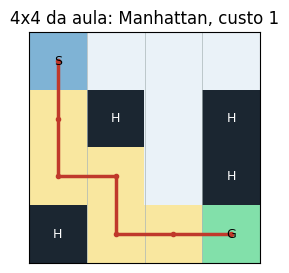

In [3]:
ax = desenhar(MAPA_AULA, r, titulo="4x4 da aula: Manhattan, custo 1")
plt.savefig(FIGURAS / "mapa_aula.png", dpi=150, bbox_inches="tight")
plt.show()

Em amarelo estão as células expandidas e em vermelho o caminho.

### Execução no Gymnasium

As ações do A* são executadas no `FrozenLake-v1` com `is_slippery=False`. O episódio precisa terminar no `G` com recompensa 1.

In [4]:
recompensa, terminou, estados = executar_no_ambiente(MAPA_AULA, r.acoes)
print(f"recompensa = {recompensa}, terminou = {terminou}, estados = {estados}")
assert terminou and recompensa == 1.0

recompensa = 1.0, terminou = True, estados = [0, 4, 8, 9, 13, 14, 15]


### Comparação com o notebook base da aula

O ponto de partida é o notebook do professor, [`Pratica_2_Completa.ipynb`](./Pratica_2_Completa.ipynb), que estava no Drive (slide 36). Ele roda o A* com Manhattan e custo 1 num mapa 8x8 próprio, com S em (0,7) e G em (7,7), e gera um GIF do agente andando. O `astar.py` mantém a mesma ideia e muda o seguinte:

| Notebook base | `astar.py` | Por quê |
|---|---|---|
| A heap guarda o caminho inteiro em cada entrada | Cada nó guarda `pai`, `acao` e `g` (slide 35), e o caminho é reconstruído no fim | Segue a estrutura de nó pedida e evita copiar listas a cada sucessor |
| `cost_function(acc_cost, a, b)` devolve o custo acumulado, e `custo_mov` é global | `custo_fn(origem, destino)` devolve só o custo do passo e é passada como parâmetro, como `heuristica_fn` | Os experimentos trocam o custo e a heurística sem editar a busca |
| O nó fechado nunca é reaberto, e todo vizinho é empilhado | Guarda o melhor g por célula, só empilha se o g melhorar e reabre um fechado se achar g menor | Com heurísticas que superestimam o custo, o caminho devolvido continua sendo o melhor encontrado |
| Empate em f desfeito pelo menor g | Empate desfeito pelo menor h e depois pela ordem de inserção | Tende a expandir menos nós, e a ordem fica determinística |
| Devolve só o caminho (ou `None`) | Devolve caminho, ações, custo, nós expandidos e gerados, tamanho máximo da fronteira, tempo e lista de fechados | Métricas necessárias para os experimentos e o relatório |
| GIF com `imageio` | `gerar_gif` com Pillow (já instalado junto com o matplotlib) | Uma dependência a menos |

No mapa do notebook base, as duas implementações encontram exatamente o mesmo caminho, com 25 passos.

In [5]:
MAPA_BASE = ["FFFFFFFS",
             "FHFHHHHH",
             "FHFFHFFF",
             "FHHFFFHF",
             "FHFHHHFF",
             "FHFFFHFH",
             "FHFHFHHH",
             "FFFHFFFG"]

CAMINHO_DO_NOTEBOOK_BASE = [(0, 7), (0, 6), (0, 5), (0, 4), (0, 3), (0, 2), (0, 1), (0, 0), (1, 0),
                            (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (7, 1), (7, 2), (6, 2),
                            (5, 2), (5, 3), (5, 4), (6, 4), (7, 4), (7, 5), (7, 6), (7, 7)]

r_base = a_star(MAPA_BASE)
validar_caminho(MAPA_BASE, r_base)
assert r_base.caminho == CAMINHO_DO_NOTEBOOK_BASE

print(grid_com_caminho(MAPA_BASE, r_base))
pd.DataFrame([r_base.metricas()])

*******S
*HFHHHHH
*HFFHFFF
*HHFFFHF
*HFHHHFF
*H***HFH
*H*H*HHH
***H***G


,encontrou,custo,passos,expandidos,gerados,max_fronteira,tempo_ms
0,True,25.0,25,38,40,2,0.54


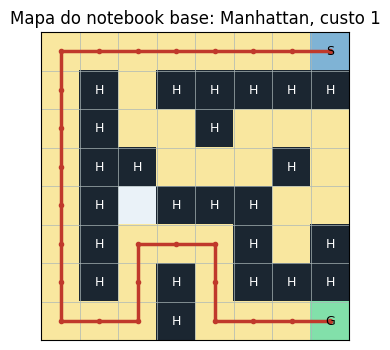

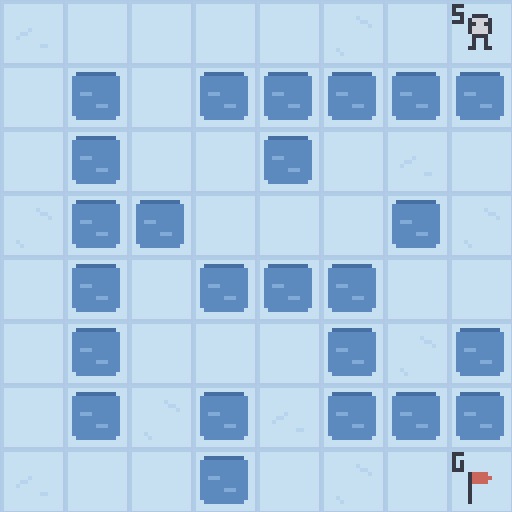

In [6]:
fig, ax = plt.subplots(figsize=(4, 4))
desenhar(MAPA_BASE, r_base, ax=ax, titulo="Mapa do notebook base: Manhattan, custo 1")
plt.savefig(FIGURAS / "mapa_base.png", dpi=150, bbox_inches="tight")
plt.show()

gerar_gif(MAPA_BASE, r_base.acoes, FIGURAS / "mapa_base.gif")
display(Image(filename=FIGURAS / "mapa_base.gif"))

Nesse mapa a Manhattan engana: o G fica logo abaixo do S, mas a fileira de buracos obriga o agente a dar a volta pela esquerda. Por isso o A* expande 38 nós para um caminho de 25 passos. Esse é um bom exemplo de mapa que engana a heurística.

### Verificação em mapas aleatórios

Para conferir a implementação fora do exemplo da aula, a busca roda em mapas aleatórios do Gymnasium (`p = 0.8`, 10 sementes por tamanho) com três heurísticas. Com uma heurística admissível, o custo precisa ser igual ao de $h = 0$ (Dijkstra), e o número de nós expandidos não pode ser maior.

Esta tabela só valida a implementação. A análise de tamanho de grid e de heurísticas fica nos experimentos de cenário.

In [7]:
linhas = []
for tamanho in (4, 8, 16, 32):
    for semente in range(10):
        mapa = generate_random_map(size=tamanho, p=0.8, seed=SEMENTE + semente)
        base = a_star(mapa, heuristica_fn=heuristica_nula)
        for nome, h in [("nula (Dijkstra)", heuristica_nula), ("manhattan", manhattan), ("euclidiana", euclidiana)]:
            res = a_star(mapa, heuristica_fn=h)
            validar_caminho(mapa, res)
            assert math.isclose(res.custo, base.custo)
            linhas.append({"tamanho": tamanho, "semente": semente, "heuristica": nome, **res.metricas()})
        rec, fim, _ = executar_no_ambiente(mapa, base.acoes)
        assert fim and rec == 1.0

df = pd.DataFrame(linhas)
df.groupby(["tamanho", "heuristica"])[["custo", "expandidos", "max_fronteira", "tempo_ms"]].mean().round(2)

custo  expandidos  max_fronteira  tempo_ms
tamanho heuristica                                                 
4       euclidiana         6.0         8.4            4.0      0.03
        manhattan          6.0         6.4            3.7      0.02
        nula (Dijkstra)    6.0        11.9            3.4      0.03
8       euclidiana        14.0        34.8           10.1      0.13
        manhattan         14.0        17.7           12.3      0.08
        nula (Dijkstra)   14.0        48.6            7.7      0.15
16      euclidiana        30.0       167.0           26.6      0.49
        manhattan         30.0        44.4           30.6      0.14
        nula (Dijkstra)   30.0       206.6           16.1      0.52
32      euclidiana        62.0       706.9           52.7      2.05
        manhattan         62.0       122.3           86.9      0.41
        nula (Dijkstra)   62.0       817.3           33.6      2.17

Os 40 mapas passam nas três verificações (caminho válido, custo igual ao de Dijkstra e recompensa 1 no Gymnasium), então a implementação está pronta para os experimentos.

---

## Experimentos de cenário

*Em construção.*

---

## Experimentos de custo

*Em construção.*